# Alanine scan figure

This notebook draws an alanine-scan figure for a peptide.

The first row is your original peptide. Each row below it replaces one residue with alanine (shown as a black **A**). Circles are coloured by amino acid class.

**To use it with your own peptide:** change `original_sequence` in the next cell, then choose **Run all**. The figure is also saved as `ala_scan.png`.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ---- Change this to your peptide (one-letter codes) ----
original_sequence = "PDEAK"

# Show row labels like WT, P1A, D2A ...
show_labels = True

# Save the figure as a file
save_figure = True
figure_name = "ala_scan.png"

## Amino acid classes and colours

Each amino acid belongs to one class only.

In [2]:
amino_acid_categories = {
    'non-polar': ['A', 'V', 'L', 'I', 'M', 'F', 'P', 'G', 'W'],
    'polar':     ['N', 'C', 'Q', 'S', 'T', 'Y'],
    'anionic':   ['D', 'E'],
    'cationic':  ['R', 'H', 'K'],
}

color_map = {
    'polar':     '#9467bd',   # purple
    'non-polar': '#ff7f0e',   # orange
    'anionic':   '#d62728',   # red
    'cationic':  '#2ca02c',   # green
}

def get_category(aa):
    for category, residues in amino_acid_categories.items():
        if aa.upper() in residues:
            return category
    raise ValueError(f"Unknown amino acid letter: {aa}")

## Make the alanine-scan sequences

In [3]:
original_sequence = original_sequence.strip().upper()

# Lowercase 'a' marks a residue that was swapped to alanine
Ala_scan_seq = [original_sequence]
row_labels = ['WT']

for i, aa in enumerate(original_sequence):
    if aa == 'A':
        continue   # already alanine, nothing to swap
    new_sequence = list(original_sequence)
    new_sequence[i] = 'a'
    Ala_scan_seq.append(''.join(new_sequence))
    row_labels.append(f"{aa}{i + 1}A")

for label, seq in zip(row_labels, Ala_scan_seq):
    print(label, seq)

WT PDEAK
P1A aDEAK
D2A PaEAK
E3A PDaAK
K5A PDEAa


## Draw the figure

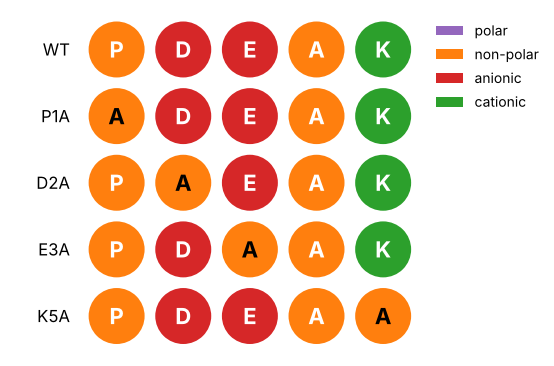

In [4]:
n_rows = len(Ala_scan_seq)
n_cols = len(original_sequence)

fig, ax = plt.subplots(figsize=(n_cols * 0.9 + 3, n_rows * 0.9))

for row, seq in enumerate(Ala_scan_seq):
    y = n_rows - row
    for col, aa in enumerate(seq):
        x = col + 1
        color = color_map[get_category(aa)]
        ax.add_patch(plt.Circle((x, y), 0.42, facecolor=color, edgecolor='none'))

        if aa == 'a':
            ax.text(x, y, 'A', color='black', ha='center', va='center',
                    fontsize=16, weight='bold')
        else:
            ax.text(x, y, aa, color='white', ha='center', va='center',
                    fontsize=16, weight='bold')

    if show_labels:
        ax.text(0.3, y, row_labels[row], ha='right', va='center', fontsize=12)

legend_elements = [Patch(facecolor=c, edgecolor='none', label=name)
                   for name, c in color_map.items()]
ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1),
          frameon=False)

ax.set_xlim(-0.6 if show_labels else 0.4, n_cols + 0.6)
ax.set_ylim(0.4, n_rows + 0.6)
ax.set_aspect('equal')
ax.axis('off')

if save_figure:
    plt.savefig(figure_name, dpi=300, bbox_inches='tight')

plt.show()